<a href="https://colab.research.google.com/github/ShahAlam1219/-Quantum-Breast-Cancer-Classification/blob/main/quantum_breast_cancer_estimator_qnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid Quantum–Classical Breast Cancer Classifier

**EstimatorQNN + gate-based variational circuit + WDBC dataset**

Run the installation cell first, then execute the code cells from top to bottom. Keep `wdbc.data` in the same directory as this notebook. The experiment maps benign/malignant labels to `-1/+1` for EstimatorQNN training and `0/1` for clinical evaluation.

Training uses exact statevector expectation values. The shot study samples the explicitly declared Pauli-Z tensor observable at finite shot counts on an ideal circuit; it does not simulate hardware gate or readout errors.


In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17)

# data (as pandas dataframes)
X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

# metadata
print(breast_cancer_wisconsin_diagnostic.metadata)

# variable information
print(breast_cancer_wisconsin_diagnostic.variables)


{'uci_id': 17, 'name': 'Breast Cancer Wisconsin (Diagnostic)', 'repository_url': 'https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic', 'data_url': 'https://archive.ics.uci.edu/static/public/17/data.csv', 'abstract': 'Diagnostic Wisconsin Breast Cancer Database.', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 569, 'num_features': 30, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Diagnosis'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1993, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C5DW2B', 'creators': ['William Wolberg', 'Olvi Mangasarian', 'Nick Street', 'W. Street'], 'intro_paper': {'ID': 230, 'type': 'NATIVE', 'title': 'Nuclear feature extraction for breast tumor diagnosis', 'authors': 'W. Street, W. Wolberg, O. Mangasarian', 'venue': 'Electronic imaging', 'year': 1993, 'journal': None, 'DOI': '1

In [ ]:
%pip install qiskit qiskit-machine-learning

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 65.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 45.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit-machine-learning]


## 1. IMPORTS AND CONFIGURATION


In [ ]:
"""Hybrid Quantum-Classical Breast Cancer Classifier using Qiskit EstimatorQNN.

Dataset: Wisconsin Diagnostic Breast Cancer (WDBC), UCI.
Positive clinical class: malignant (M).
EstimatorQNN training labels: benign=-1, malignant=+1.
Clinical metric labels: benign=0, malignant=1.
"""

from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay,
)

from qiskit import transpile
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms.classifiers import NeuralNetworkClassifier
from qiskit_machine_learning.optimizers import COBYLA


# Put wdbc.data in the same folder as this script, or change DATA_PATH.
try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:  # Allows the same code to run inside a Jupyter notebook.
    BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / "wdbc.data"
OUTPUT_DIR = BASE_DIR / "quantum_breast_cancer_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
TEST_SIZE = 0.20
NUM_QUBITS = 4                 # Four PCA components -> four input qubits
FEATURE_MAP_REPS = 1
ANSATZ_REPS = 2                 # Number of trainable variational layers
MAX_QNN_TRAIN_SAMPLES = 180     # Set to None to train on the complete training split
COBYLA_MAXITER = 60
NOISE_SHOTS = [128, 512, 2048]  # Shot-equivalent noise study; see limitation below
NOISE_REPEATS = 3

# Label mapping is deliberately explicit.
CLINICAL_LABELS = {"B": 0, "M": 1}       # Metrics: malignant is positive class
QNN_LABELS = {"B": -1, "M": 1}          # EstimatorQNN binary output is in [-1, +1]

FEATURE_BASES = [
    "radius", "texture", "perimeter", "area", "smoothness",
    "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension",
]
FEATURE_NAMES = (
    [f"{name}_mean" for name in FEATURE_BASES]
    + [f"{name}_se" for name in FEATURE_BASES]
    + [f"{name}_worst" for name in FEATURE_BASES]
)
COLUMNS = ["id", "diagnosis"] + FEATURE_NAMES




## 2. LOAD AND PREPARE THE WDBC DATASET


In [ ]:
# Map the fetched dataset columns (radius1, texture1, etc.) to the expected FEATURE_NAMES
df = X.copy()
df.columns = FEATURE_NAMES

# Map diagnosis labels to a single column
df["diagnosis"] = y["Diagnosis"].astype(str).str.strip()

if not set(df["diagnosis"].unique()).issubset(CLINICAL_LABELS):
    raise ValueError("Diagnosis must contain only 'B' (benign) and 'M' (malignant).")

if df[FEATURE_NAMES].isna().any().any():
    raise ValueError("Missing feature values were found; inspect the input file before training.")

X_data = df[FEATURE_NAMES].astype(float)
y01 = df["diagnosis"].map(CLINICAL_LABELS).astype(int)  # B=0, M=1
sample_ids = df.index

print("DATASET SUMMARY")
print(f"Rows: {len(df)} | Features: {X_data.shape[1]} | Missing feature values: {int(df[FEATURE_NAMES].isna().sum().sum())}")
print("Diagnosis counts (B=benign, M=malignant):")
print(df["diagnosis"].value_counts().sort_index())
print("Clinical mapping:", CLINICAL_LABELS)
print("EstimatorQNN training mapping:", QNN_LABELS)

X_train_df, X_test_df, y_train_01, y_test_01, id_train, id_test = train_test_split(
    X_data,
    y01,
    sample_ids,
    test_size=TEST_SIZE,
    stratify=y01,
    random_state=SEED,
)
y_train_01 = np.asarray(y_train_01, dtype=int)
y_test_01 = np.asarray(y_test_01, dtype=int)

standard_scaler = StandardScaler()
X_train_std = standard_scaler.fit_transform(X_train_df)
X_test_std = standard_scaler.transform(X_test_df)

pca = PCA(n_components=NUM_QUBITS, random_state=SEED)
X_train_pca = pca.fit_transform(X_train_std)
X_test_pca = pca.transform(X_test_std)

angle_scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))
X_train_quantum_all = angle_scaler.fit_transform(X_train_pca)
X_test_quantum = angle_scaler.transform(X_test_pca)
X_train_quantum_all = np.clip(X_train_quantum_all, -np.pi, np.pi)
X_test_quantum = np.clip(X_test_quantum, -np.pi, np.pi)

if MAX_QNN_TRAIN_SAMPLES is not None and MAX_QNN_TRAIN_SAMPLES < len(X_train_quantum_all):
    X_train_model, _, y_train_model_01, _ = train_test_split(
        X_train_quantum_all,
        y_train_01,
        train_size=MAX_QNN_TRAIN_SAMPLES,
        stratify=y_train_01,
        random_state=SEED,
    )
else:
    X_train_model = X_train_quantum_all
    y_train_model_01 = y_train_01

y_train_qnn = np.where(y_train_model_01 == 1, 1.0, -1.0)

print(f"\nTrain samples used by all models: {len(X_train_model)}")
print(f"Held-out test samples: {len(X_test_quantum)}")
print("PCA explained variance by component:", np.round(pca.explained_variance_ratio_, 4))
print(f"Total variance retained by {NUM_QUBITS} PCA components: {pca.explained_variance_ratio_.sum():.4f}")

DATASET SUMMARY
Rows: 569 | Features: 30 | Missing feature values: 0
Diagnosis counts (B=benign, M=malignant):
diagnosis
B    357
M    212
Name: count, dtype: int64
Clinical mapping: {'B': 0, 'M': 1}
EstimatorQNN training mapping: {'B': -1, 'M': 1}

Train samples used by all models: 180
Held-out test samples: 114
PCA explained variance by component: [0.4459 0.1855 0.0958 0.0659]
Total variance retained by 4 PCA components: 0.7932


## 3. BUILD AND TRAIN THE GATE-BASED ESTIMATORQNN CLASSIFIER


In [ ]:
# Feature map: encodes the four PCA features as quantum rotation/entangling gates.
feature_map = zz_feature_map(
    feature_dimension=NUM_QUBITS,
    reps=FEATURE_MAP_REPS,
    entanglement="linear",
)

# Ansatz: trainable variational rotation and entanglement layers.
ansatz = real_amplitudes(
    num_qubits=NUM_QUBITS,
    reps=ANSATZ_REPS,
    entanglement="linear",
)

# Compose data-encoding and trainable circuits into one parameterized circuit.
quantum_circuit = feature_map.compose(ansatz)
input_parameters = list(feature_map.parameters)
weight_parameters = list(ansatz.parameters)

# Declare one measured observable explicitly: Z tensor Z tensor Z tensor Z.
# Its measurement outcomes are +1 or -1, matching the EstimatorQNN label mapping.
measurement_observable = SparsePauliOp("Z" * NUM_QUBITS)

# Exact local statevector Estimator: no finite-shot sampling is used during training.
exact_estimator = StatevectorEstimator(default_precision=0.0, seed=SEED)
estimator_qnn = EstimatorQNN(
    circuit=quantum_circuit,
    estimator=exact_estimator,
    observables=measurement_observable,
    input_params=input_parameters,
    weight_params=weight_parameters,
)

rng = np.random.default_rng(SEED)
initial_weights = rng.uniform(-0.1, 0.1, size=estimator_qnn.num_weights)
training_losses = []

def training_callback(weights, objective_value):
    """Store the optimizer objective so the training curve can be plotted."""
    training_losses.append(float(objective_value))

quantum_classifier = NeuralNetworkClassifier(
    neural_network=estimator_qnn,
    loss="squared_error",
    optimizer=COBYLA(maxiter=COBYLA_MAXITER),
    initial_point=initial_weights,
    callback=training_callback,
)

print("\nTraining EstimatorQNN ...")
qnn_train_start = time.perf_counter()
quantum_classifier.fit(X_train_model, y_train_qnn)
qnn_training_seconds = time.perf_counter() - qnn_train_start
print(f"EstimatorQNN training completed in {qnn_training_seconds:.2f} seconds")





Training EstimatorQNN ...
EstimatorQNN training completed in 17.16 seconds


## 4. TRAIN CLASSICAL BASELINES AND EVALUATE ALL MODELS


In [ ]:
# Fair comparison: both classical baselines use the same four PCA inputs and training rows.
classical_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(16, 8),
        activation="relu",
        solver="adam",
        alpha=1e-3,
        max_iter=1000,
        early_stopping=True,
        n_iter_no_change=30,
        random_state=SEED,
    ),
}

classical_results = {}
for model_name, model in classical_models.items():
    start = time.perf_counter()
    model.fit(X_train_model, y_train_model_01)
    train_seconds = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(X_test_quantum).astype(int)
    probabilities = model.predict_proba(X_test_quantum)[:, 1]
    inference_seconds = time.perf_counter() - start

    classical_results[model_name] = {
        "model": model,
        "y_pred": predictions,
        "y_score": probabilities,
        "train_seconds": train_seconds,
        "inference_seconds": inference_seconds,
    }

# EstimatorQNN expectation values are in [-1,+1]. Convert them to a unit interval
# for ROC AUC; this is a monotonic score mapping, not a calibrated clinical probability.
start = time.perf_counter()
qnn_signed_predictions = np.asarray(quantum_classifier.predict(X_test_quantum)).reshape(-1)
qnn_expectations = np.asarray(
    estimator_qnn.forward(X_test_quantum, quantum_classifier.weights)
).reshape(-1)
qnn_inference_seconds = time.perf_counter() - start
qnn_predictions = (qnn_signed_predictions > 0).astype(int)
qnn_scores_01 = np.clip((qnn_expectations + 1.0) / 2.0, 0.0, 1.0)


def calculate_metrics(y_true, y_pred, y_score):
    """Return requested binary-classification metrics; class 1 is malignant."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Precision (malignant)": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall / Sensitivity": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Specificity": specificity,
        "ROC AUC": roc_auc_score(y_true, y_score),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }

results = {
    "EstimatorQNN": {
        "y_pred": qnn_predictions,
        "y_score": qnn_scores_01,
        "train_seconds": qnn_training_seconds,
        "inference_seconds": qnn_inference_seconds,
    }
}
for model_name, result in classical_results.items():
    results[model_name] = result

metric_rows = []
for model_name, result in results.items():
    row = {"Model": model_name}
    row.update(calculate_metrics(y_test_01, result["y_pred"], result["y_score"]))
    row["Training time (s)"] = result["train_seconds"]
    row["Inference time (s)"] = result["inference_seconds"]
    row["Inference time (ms/sample)"] = 1000 * result["inference_seconds"] / len(y_test_01)
    metric_rows.append(row)

metrics_df = pd.DataFrame(metric_rows).set_index("Model")
print("\nHELD-OUT TEST RESULTS (malignant = positive class)")
print(metrics_df.round(4).to_string())
metrics_df.to_csv(OUTPUT_DIR / "metrics_comparison.csv")

print("\nEstimatorQNN classification report:")
print(
    pd.crosstab(
        pd.Series(y_test_01, name="Actual (0=benign, 1=malignant)"),
        pd.Series(qnn_predictions, name="Predicted (0=benign, 1=malignant)"),
    )
)

# Save individual test predictions, including source record IDs.
predictions_df = pd.DataFrame({
    "id": np.asarray(id_test),
    "actual_diagnosis_0_benign_1_malignant": y_test_01,
    "estimator_qnn_prediction": qnn_predictions,
    "estimator_qnn_expectation_value": qnn_expectations,
    "estimator_qnn_unit_interval_score_not_calibrated": qnn_scores_01,
    "logistic_regression_prediction": classical_results["Logistic Regression"]["y_pred"],
    "mlp_prediction": classical_results["MLP"]["y_pred"],
})
predictions_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)





HELD-OUT TEST RESULTS (malignant = positive class)
                     Accuracy  Macro F1  Precision (malignant)  Recall / Sensitivity  Specificity  ROC AUC  TN  FP  FN  TP  Training time (s)  Inference time (s)  Inference time (ms/sample)
Model                                                                                                                                                                                        
EstimatorQNN           0.4737    0.4602                 0.3333                0.4286       0.5000   0.4544  36  36  24  18            17.1640              0.3552                      3.1154
Logistic Regression    0.9561    0.9521                 0.9744                0.9048       0.9861   0.9967  71   1   4  38             0.0252              0.0007                      0.0061
MLP                    0.6316    0.3871                 0.0000                0.0000       1.0000   0.4398  72   0  42   0             0.0375              0.0005                      0.004

## 5. CONFUSION MATRICES, ROC CURVES, TRAINING CURVE, AND COMPARISON PLOT


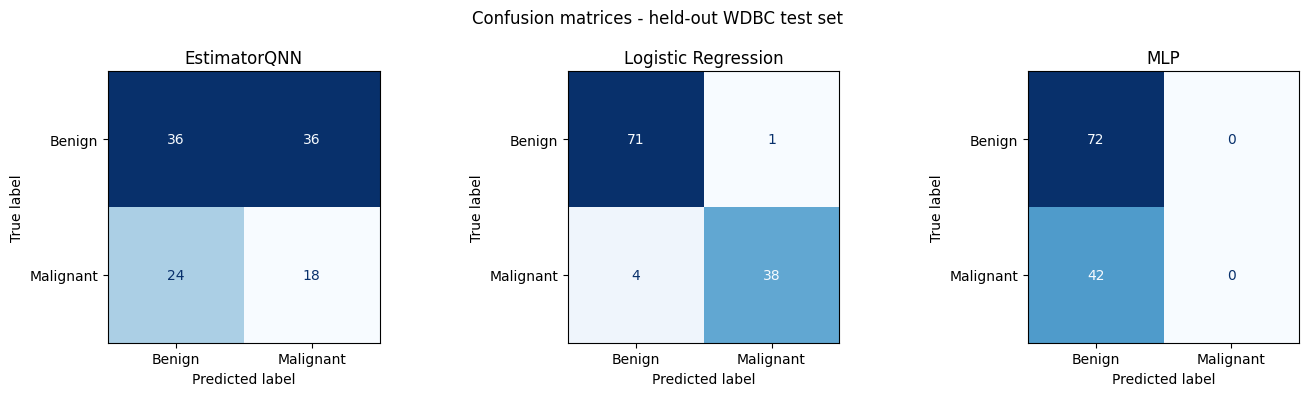

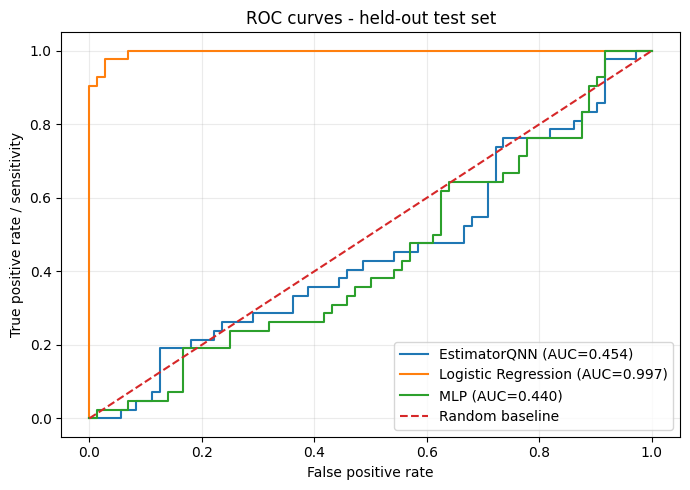

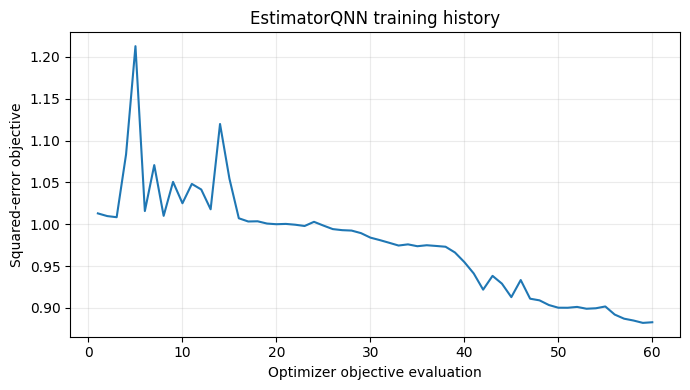

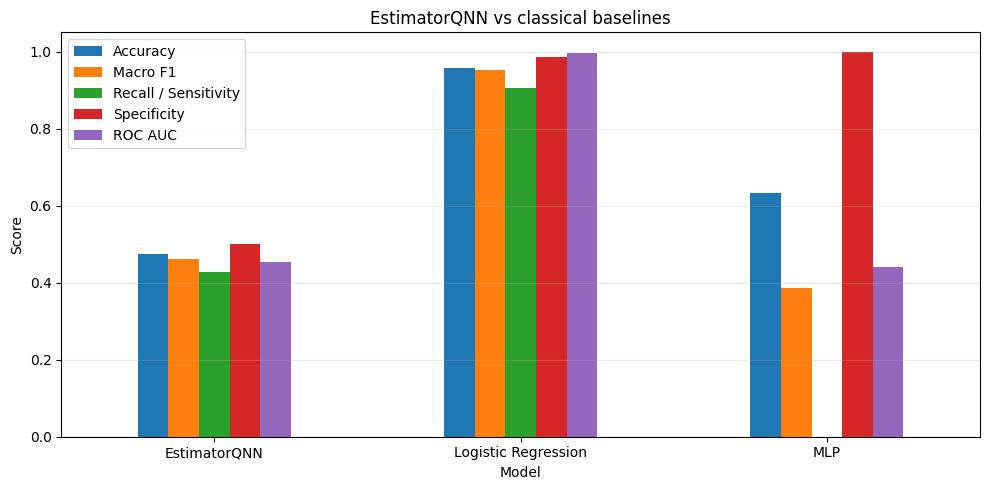

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (model_name, result) in zip(axes, results.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test_01,
        result["y_pred"],
        labels=[0, 1],
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(model_name)
fig.suptitle("Confusion matrices - held-out WDBC test set")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 5))
for model_name, result in results.items():
    fpr, tpr, _ = roc_curve(y_test_01, result["y_score"])
    auc_value = roc_auc_score(y_test_01, result["y_score"])
    plt.plot(fpr, tpr, label=f"{model_name} (AUC={auc_value:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate / sensitivity")
plt.title("ROC curves - held-out test set")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curves.png", dpi=160, bbox_inches="tight")
plt.show()

if training_losses:
    plt.figure(figsize=(7, 4))
    plt.plot(range(1, len(training_losses) + 1), training_losses)
    plt.xlabel("Optimizer objective evaluation")
    plt.ylabel("Squared-error objective")
    plt.title("EstimatorQNN training history")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "qnn_training_curve.png", dpi=160, bbox_inches="tight")
    plt.show()

metric_columns = ["Accuracy", "Macro F1", "Recall / Sensitivity", "Specificity", "ROC AUC"]
metrics_df[metric_columns].plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05))
plt.ylabel("Score")
plt.title("EstimatorQNN vs classical baselines")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_metric_comparison.png", dpi=160, bbox_inches="tight")
plt.show()




## 6. QUANTUM RESOURCE ACCOUNTING


In [ ]:
# This is a backend-independent transpilation proxy, not a hardware-specific compiled circuit.
compiled_circuit = transpile(
    quantum_circuit,
    basis_gates=["rz", "sx", "x", "cx"],
    optimization_level=1,
    seed_transpiler=SEED,
)
compiled_depth = int(compiled_circuit.depth())
compiled_ops = compiled_circuit.count_ops()
two_qubit_gate_count = int(
    sum(count for gate_name, count in compiled_ops.items() if gate_name in {"cx", "cz", "ecr", "iswap"})
)

observables_value = estimator_qnn.observables
observable_count = len(observables_value) if isinstance(observables_value, (list, tuple)) else 1

resource_summary = {
    "qubits": int(NUM_QUBITS),
    "feature_map": "ZZ feature map",
    "feature_map_repetitions": int(FEATURE_MAP_REPS),
    "ansatz": "RealAmplitudes",
    "ansatz_layers_repetitions": int(ANSATZ_REPS),
    "compiled_depth_backend_independent_proxy": compiled_depth,
    "compiled_two_qubit_gate_count_proxy": two_qubit_gate_count,
    "compiled_operation_counts": {str(k): int(v) for k, v in compiled_ops.items()},
    "input_parameters": int(estimator_qnn.num_inputs),
    "trainable_parameters": int(estimator_qnn.num_weights),
    "total_circuit_parameters": int(len(quantum_circuit.parameters)),
    "observable_count": int(observable_count),
    "observable": "Z" * NUM_QUBITS,
    "shots": "Exact statevector for training; ideal Pauli measurement sampling for sensitivity study",
    "training_execution": "Exact statevector expectation values (no finite shots)",
    "noise_study_shots": NOISE_SHOTS,
    "qnn_training_time_seconds": float(qnn_training_seconds),
    "qnn_test_inference_time_seconds": float(qnn_inference_seconds),
    "qnn_test_inference_ms_per_sample": float(1000 * qnn_inference_seconds / len(y_test_01)),
    "training_samples_used": int(len(X_train_model)),
    "test_samples": int(len(X_test_quantum)),
    "pca_variance_retained": float(pca.explained_variance_ratio_.sum()),
}

print("\nQUANTUM RESOURCE SUMMARY")
for key, value in resource_summary.items():
    print(f"{key}: {value}")
with open(OUTPUT_DIR / "quantum_resource_summary.json", "w", encoding="utf-8") as file:
    json.dump(resource_summary, file, indent=2)

with open(OUTPUT_DIR / "quantum_circuit.txt", "w", encoding="utf-8") as file:
    file.write(str(quantum_circuit.draw(output="text")))
np.save(OUTPUT_DIR / "estimator_qnn_trained_weights.npy", quantum_classifier.weights)





QUANTUM RESOURCE SUMMARY
qubits: 4
feature_map: ZZ feature map
feature_map_repetitions: 1
ansatz: RealAmplitudes
ansatz_layers_repetitions: 2
compiled_depth_backend_independent_proxy: 29
compiled_two_qubit_gate_count_proxy: 12
compiled_operation_counts: {'rz': 39, 'sx': 28, 'cx': 12}
input_parameters: 4
trainable_parameters: 12
total_circuit_parameters: 16
observable_count: 1
observable: ZZZZ
shots: Exact statevector for training; ideal Pauli measurement sampling for sensitivity study
training_execution: Exact statevector expectation values (no finite shots)
noise_study_shots: [128, 512, 2048]
qnn_training_time_seconds: 17.163995015000182
qnn_test_inference_time_seconds: 0.35515040300015244
qnn_test_inference_ms_per_sample: 3.115354412282039
training_samples_used: 180
test_samples: 114
pca_variance_retained: 0.7931718711164907


## 7. SHOT-NOISE SENSITIVITY STUDY (FINITE-SHOT MEASUREMENT SAMPLING)



SHOT-NOISE SENSITIVITY (ideal Pauli measurement, finite-shot sampling)
 Shots               Metric   Mean  Std across repeats
   128             Accuracy 0.4620              0.0109
   128 Recall / Sensitivity 0.4524              0.0194
   128              ROC AUC 0.4684              0.0180
   512             Accuracy 0.4620              0.0180
   512 Recall / Sensitivity 0.4206              0.0224
   512              ROC AUC 0.4597              0.0035
  2048             Accuracy 0.4766              0.0083
  2048 Recall / Sensitivity 0.4286              0.0000
  2048              ROC AUC 0.4543              0.0044


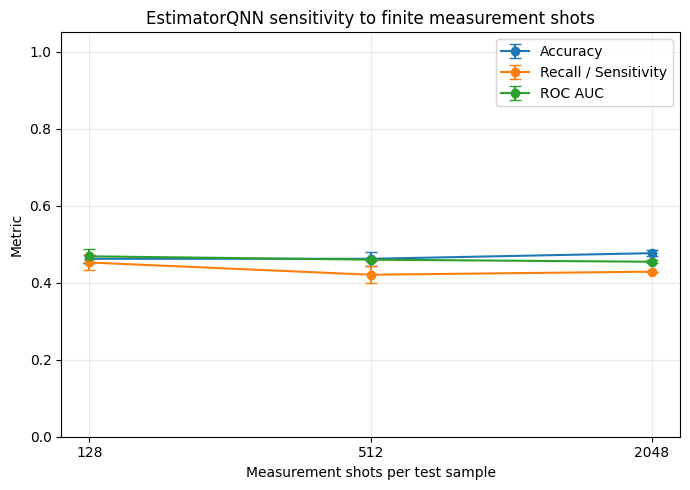

In [ ]:
# The declared observable is Z tensor ... tensor Z, whose outcomes are +1 or -1.
# If its ideal expectation is mu, one shot returns +1 with probability (1+mu)/2
# and -1 otherwise. Binomial sampling below therefore simulates finite measurement
# shots on an ideal circuit. It does NOT simulate gate errors, readout errors, or a QPU.
noise_rows = []
ideal_plus_probabilities = np.clip((1.0 + qnn_expectations) / 2.0, 0.0, 1.0)

for shots in NOISE_SHOTS:
    repeat_metrics = []

    for repeat in range(NOISE_REPEATS):
        shot_rng = np.random.default_rng(SEED + repeat + shots)
        plus_counts = shot_rng.binomial(n=shots, p=ideal_plus_probabilities)
        sampled_expectations = (2.0 * plus_counts / shots) - 1.0
        sampled_predictions = (sampled_expectations >= 0.0).astype(int)
        sampled_scores = np.clip((sampled_expectations + 1.0) / 2.0, 0.0, 1.0)
        repeat_metrics.append(
            calculate_metrics(y_test_01, sampled_predictions, sampled_scores)
        )

    for metric_name in ["Accuracy", "Macro F1", "Recall / Sensitivity", "Specificity", "ROC AUC"]:
        values = [item[metric_name] for item in repeat_metrics]
        noise_rows.append({
            "Shots": shots,
            "Metric": metric_name,
            "Mean": float(np.mean(values)),
            "Std across repeats": float(np.std(values, ddof=0)),
        })

noise_df = pd.DataFrame(noise_rows)
noise_df.to_csv(OUTPUT_DIR / "noise_sensitivity.csv", index=False)
print("\nSHOT-NOISE SENSITIVITY (ideal Pauli measurement, finite-shot sampling)")
print(noise_df[noise_df["Metric"].isin(["Accuracy", "Recall / Sensitivity", "ROC AUC"])].round(4).to_string(index=False))

noise_plot = noise_df[noise_df["Metric"].isin(["Accuracy", "Recall / Sensitivity", "ROC AUC"])]
plt.figure(figsize=(7, 5))
for metric_name in noise_plot["Metric"].unique():
    part = noise_plot[noise_plot["Metric"] == metric_name]
    plt.errorbar(
        part["Shots"],
        part["Mean"],
        yerr=part["Std across repeats"],
        marker="o",
        capsize=4,
        label=metric_name,
    )
plt.xscale("log", base=2)
plt.xticks(NOISE_SHOTS, [str(value) for value in NOISE_SHOTS])
plt.ylim(0, 1.05)
plt.xlabel("Measurement shots per test sample")
plt.ylabel("Metric")
plt.title("EstimatorQNN sensitivity to finite measurement shots")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "noise_sensitivity.png", dpi=160, bbox_inches="tight")
plt.show()




## 8. FINAL RUN SUMMARY


In [ ]:
print("\nPROJECT RUN COMPLETED")
print(f"All result files are saved in: {OUTPUT_DIR.resolve()}")
print("Main files:")
for name in [
    "metrics_comparison.csv",
    "test_predictions.csv",
    "quantum_resource_summary.json",
    "noise_sensitivity.csv",
    "confusion_matrices.png",
    "roc_curves.png",
    "model_metric_comparison.png",
    "qnn_training_curve.png",
    "noise_sensitivity.png",
    "quantum_circuit.txt",
    "estimator_qnn_trained_weights.npy",
]:
    print(" -", name)

print(
    "\nInterpretation note: this experiment compares a small EstimatorQNN with "
    "classical baselines on the same four PCA components. It does not establish "
    "quantum advantage or clinical readiness."
)



PROJECT RUN COMPLETED
All result files are saved in: /content/quantum_breast_cancer_outputs
Main files:
 - metrics_comparison.csv
 - test_predictions.csv
 - quantum_resource_summary.json
 - noise_sensitivity.csv
 - confusion_matrices.png
 - roc_curves.png
 - model_metric_comparison.png
 - qnn_training_curve.png
 - noise_sensitivity.png
 - quantum_circuit.txt
 - estimator_qnn_trained_weights.npy

Interpretation note: this experiment compares a small EstimatorQNN with classical baselines on the same four PCA components. It does not establish quantum advantage or clinical readiness.
